# Experiment 4: Artificial Neural Network - Backpropagation
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Build an **Artificial Neural Network** by implementing the **Backpropagation** algorithm from scratch (NumPy) and test it on appropriate data sets (XOR and Iris).

## Algorithm (one hidden layer, sigmoid units, squared error)
1. Forward pass: `a1 = sigma(X W1 + b1)`, `a2 = sigma(a1 W2 + b2)`.
2. Output error: `d2 = (a2 - y) * a2 * (1 - a2)`.
3. Hidden error: `d1 = (d2 W2^T) * a1 * (1 - a1)`.
4. Update: `W2 -= lr * a1^T d2`, `W1 -= lr * X^T d1` (and biases).
5. Repeat for many epochs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class NeuralNetwork:
    def __init__(self, n_in, n_hidden, n_out, lr=0.5, seed=1):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, 1, (n_in, n_hidden))
        self.b1 = np.zeros((1, n_hidden))
        self.W2 = rng.normal(0, 1, (n_hidden, n_out))
        self.b2 = np.zeros((1, n_out))
        self.lr = lr
        self.loss_history = []

    def forward(self, X):
        self.a1 = sigmoid(X @ self.W1 + self.b1)
        self.a2 = sigmoid(self.a1 @ self.W2 + self.b2)
        return self.a2

    def backward(self, X, y):
        m = X.shape[0]
        d2 = (self.a2 - y) * self.a2 * (1 - self.a2)          # output-layer error
        d1 = (d2 @ self.W2.T) * self.a1 * (1 - self.a1)        # hidden-layer error
        self.W2 -= self.lr * (self.a1.T @ d2) / m
        self.b2 -= self.lr * d2.mean(axis=0, keepdims=True)
        self.W1 -= self.lr * (X.T @ d1) / m
        self.b1 -= self.lr * d1.mean(axis=0, keepdims=True)

    def fit(self, X, y, epochs=5000):
        for _ in range(epochs):
            out = self.forward(X)
            self.loss_history.append(0.5 * np.mean((out - y) ** 2))
            self.backward(X, y)

    def predict(self, X):
        return self.forward(X)

### Test 1: XOR problem (not linearly separable)

Input -> predicted probability -> class
[0. 0.] -> [0.0114] -> 0
[0. 1.] -> [0.9869] -> 1
[1. 0.] -> [0.9843] -> 1
[1. 1.] -> [0.0178] -> 0

Final loss: 0.000109


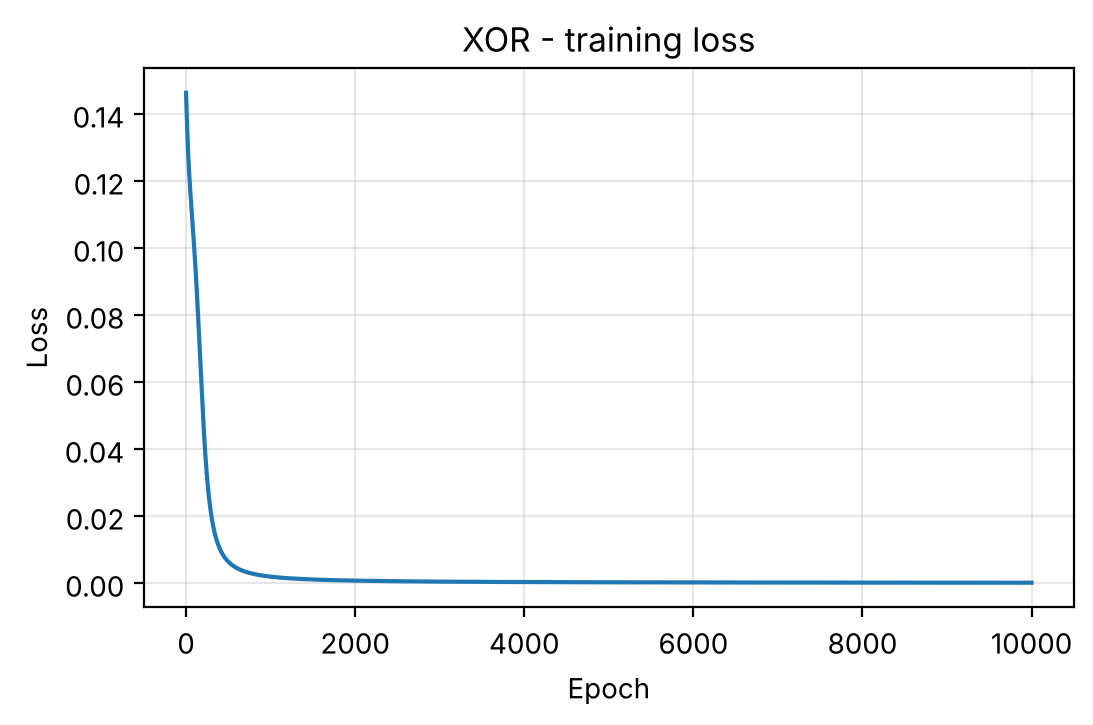

In [2]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

nn_xor = NeuralNetwork(2, 4, 1, lr=2.0, seed=3)
nn_xor.fit(X, y, epochs=10000)

print('Input -> predicted probability -> class')
for xi, p in zip(X, nn_xor.predict(X)):
    print(xi, '->', np.round(p, 4), '->', int(p[0] > 0.5))
print('\nFinal loss:', round(nn_xor.loss_history[-1], 6))

plt.figure(figsize=(6, 3.5))
plt.plot(nn_xor.loss_history)
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('XOR - training loss')
plt.grid(alpha=0.3); plt.show()

### Test 2: Iris data set (3 classes)

Training accuracy: 0.9833
Test accuracy    : 0.9667

Confusion matrix (test):
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


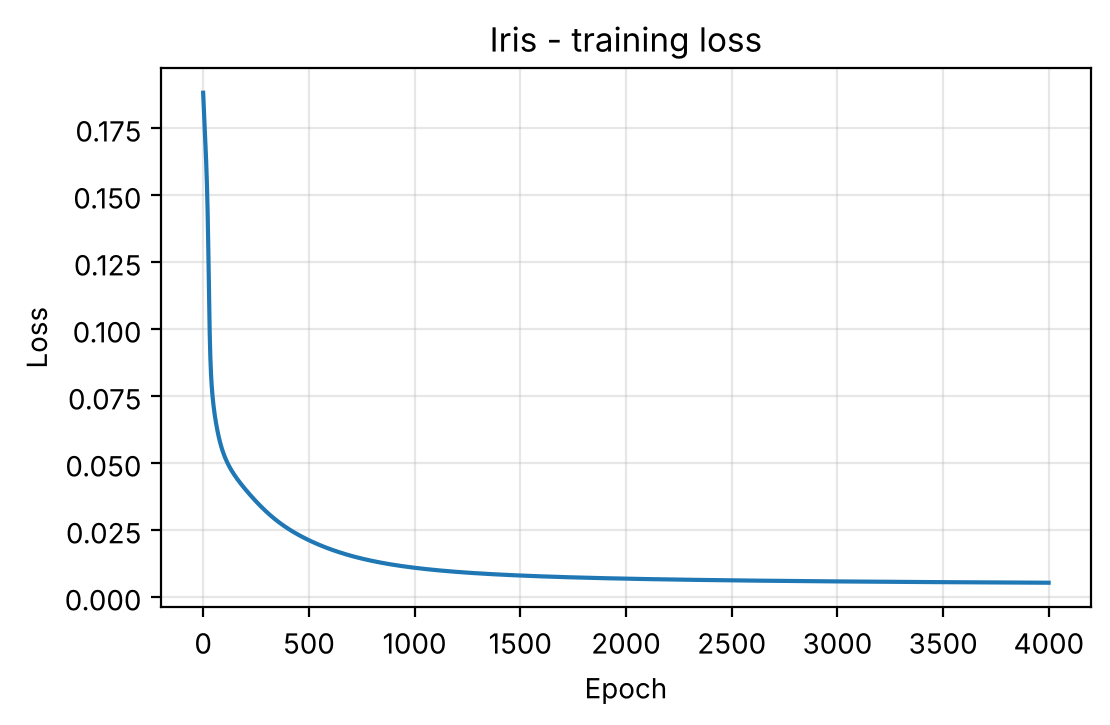

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

iris = load_iris()
Xi, yi = iris.data, iris.target
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.2, random_state=42, stratify=yi)

scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
Ytr = np.eye(3)[ytr]                                   # one-hot targets

nn = NeuralNetwork(4, 8, 3, lr=0.5, seed=7)
nn.fit(Xtr_s, Ytr, epochs=4000)

pred_tr = nn.predict(Xtr_s).argmax(axis=1)
pred_te = nn.predict(Xte_s).argmax(axis=1)
print('Training accuracy:', round(accuracy_score(ytr, pred_tr), 4))
print('Test accuracy    :', round(accuracy_score(yte, pred_te), 4))
print('\nConfusion matrix (test):\n', confusion_matrix(yte, pred_te))

plt.figure(figsize=(6, 3.5))
plt.plot(nn.loss_history)
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Iris - training loss')
plt.grid(alpha=0.3); plt.show()

## Result
The back-propagation network learns the non-linear XOR function and classifies the Iris data set with high accuracy on unseen test data; the loss curves show steady convergence.